# GRANAP, 1: your first root cross-section

**What you will learn:** generate a root cross-section with GRANAP's default parameters, read its tissues (a table
per tissue, a table per cell), and draw it.

**You need:** basic Python (running a cell, calling a function). No knowledge of plant anatomy models or of metafspm
is assumed. **Run time:** about 10 seconds.

This is the first of five user tutorials:

| | notebook | what you do |
|---|---|---|
| 1 | `01_first_run.ipynb` | generate a root cross-section with the default parameters, read its tissues, draw it |
| 2 | `02_change_a_parameter.ipynb` | find the parameters, change one, compare; the role of chance; another preset |
| 3 | `03_combine_parameters.ipynb` | explore two parameters together |
| 4 | `04_sensitivity_analysis.ipynb` | find which parameters matter most |
| 5 | `05_experimental_data.ipynb` | build a section from measured traits, compare with observations, fit a parameter |

Developers who want to understand how the model is written and ported will find a second series in
`../developer/`, best read after this one.

## What GRANAP represents

Cut a root across and look at the slice under a microscope: you see a **cross-section**, made of concentric rings of
cells, the **tissues**. From the outside in, in a young monocotyledon root such as maize or wheat:

- the **epidermis**, the root's skin, one layer of small cells in contact with the soil;
- the **exodermis**, a layer just below it that can become a barrier;
- the **cortex**, several layers of large cells, the bulk of the section. Air can fill spaces between its cells
  (**intercellular spaces**) or large channels where cells died (**aerenchyma**);
- the **endodermis**, a single ring of cells, the main barrier between the cortex and the centre;
- the **pericycle**, a ring of small cells just inside it;
- the **stele**, the central cylinder. It holds the **xylem vessels**, which carry water up to the shoot (the large
  **metaxylem** and the small **protoxylem**), and the **phloem**, which carries sugars down from the leaves.

**GRANAP** (the Python translation of GRANAR, Heymans et al., 2020) generates such sections from a description of
the tissues: the number of layers of each, the size of their cells, the diameter of the stele, the number and size of
the vessels. Each cell is drawn as a polygon; the walls between cells and the junctions between walls form a network,
on which other models (MECHA) compute water flows.

*Reference:* Heymans A., Couvreur V., LaRue T., Paez-Garcia A., Lobet G. (2020). GRANAR, a computational tool to
better understand the functional importance of monocotyledon root anatomy. *Plant Physiology* 182, 707–720.

*A word on metafspm:* this package is written with metafspm, a framework in which plant models are built as
**components** that can be combined (an architecture model, an anatomy model, a water flow model...). You do not need
to know it to use GRANAP; the developer tutorials and metafspm's own tutorial explain it.

## 1. Generate a section

`simulate` generates one root cross-section. With no argument, it uses GRANAP's **default parameters**, those of a
monocotyledon root (GRANAP's preset `for_root`). Lengths in GRANAP are in millimetres (mm); cell sizes are often
easier to read in micrometres (µm, a thousandth of a millimetre).

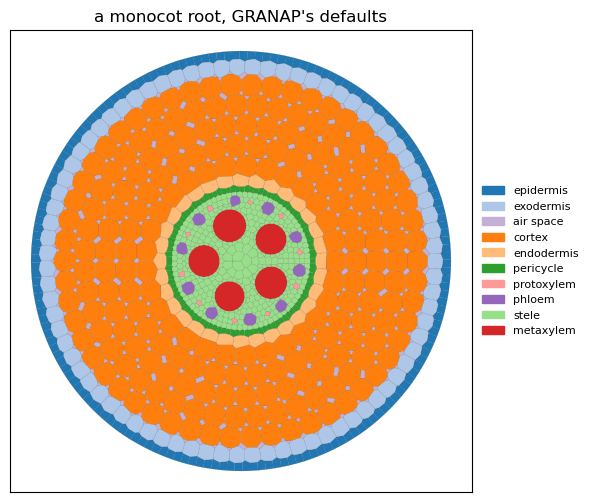

In [1]:
import matplotlib.pyplot as plt

from openalea.granap.simulation import simulate

section = simulate()
section.draw()
plt.title("a monocot root, GRANAP's defaults");

## 2. The tissues: one row per tissue

`section.summary` is a table (a pandas DataFrame) with one row per tissue, from the outside in:

| column | meaning | unit |
|---|---|---|
| `tissue` | the tissue's name | – |
| `cells` | its number of cells | – |
| `mean_cell_diameter` | the mean diameter of its cells (of a disc of the same area) | µm |
| `area` | the area of its cells | mm² |
| `area_share` | its share of the section's cell area | 0 to 1 |

The air spaces are listed as a tissue of their own, `air space`.

In [2]:
section.summary

,tissue,cells,mean_cell_diameter,area,area_share
0,epidermis,168,18.085711,0.043191,0.081756
1,exodermis,79,33.024793,0.067680,0.128111
2,air space,367,7.583423,0.017840,0.033770
3,cortex,206,43.878312,0.311561,0.589751
4,endodermis,32,28.723686,0.020738,0.039254
5,pericycle,97,11.530741,0.010150,0.019212
6,protoxylem,10,10.326936,0.000845,0.001599
7,phloem,10,23.464962,0.004338,0.008211
8,stele,406,10.398389,0.036925,0.069895
9,metaxylem,5,61.822353,0.015025,0.028441


**Reading the table.** The cortex holds 59 % of the section's area with only 206 cells: its cells are large (about
44 µm). The stele has twice as many cells (406) in 7 % of the area: its cells are small (about 10 µm). The 5 metaxylem
vessels (about 62 µm across) are the largest elements of the section.

## 3. The section as a whole

`section.totals` sums the section up: its radius (mm), its area (mm²), its number of cells (air spaces excluded), its
number of xylem vessels and their mean diameter (µm), and the share of its area that is air.

In [3]:
section.totals

radius                     0.410287
area                       0.528841
cells                   1013.000000
vessels                   15.000000
mean_vessel_diameter      27.492075
air_share                  0.033770
dtype: float64

The radius follows from the parameters: half the stele's diameter (0.27 / 2 mm), plus, for each ring of tissue, its
number of layers times its cells' diameter (5 cortex layers of 40 µm give 0.2 mm, for instance). Here
0.135 + 0.01 + 0.02 + 0.2 + 0.03 + 0.015 = 0.41 mm, as computed.

## 4. Every cell

`section.cells()` lists the cells, one row each: its `tissue`, its `area` (mm²), its `diameter` (µm), its centre
`x`, `y` and its `distance` from the section's centre (mm). The rows are ordinary pandas data: they can be filtered,
summed or grouped. Here, each cell's size against its distance from the centre shows the rings of tissues:

1380 cells and air spaces


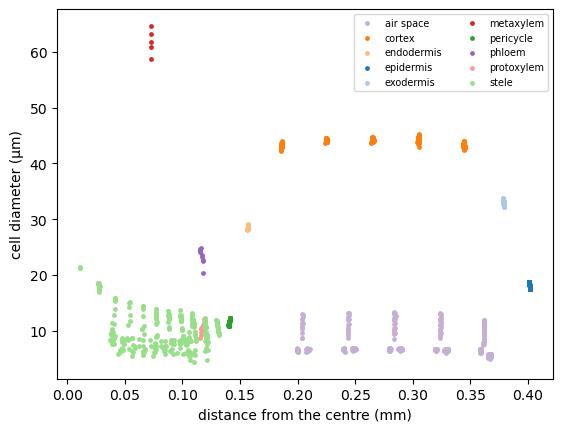

In [4]:
from openalea.granap.metafspm.plots import tissue_colour       # the drawing's colours

cells = section.cells()
print(len(cells), "cells and air spaces")
for tissue, of_tissue in cells.groupby("tissue"):
    plt.scatter(of_tissue["distance"], of_tissue["diameter"], s=6, label=tissue, color=tissue_colour(tissue))
plt.xlabel("distance from the centre (mm)"); plt.ylabel("cell diameter (µm)")
plt.legend(fontsize=7, ncol=2);

In [5]:
# The cortex cells only
cortex = cells[cells["tissue"] == "cortex"]
cortex["diameter"].describe()

count    206.000000
mean      43.878312
std        0.621064
min       42.241589
25%       43.425790
50%       43.952856
75%       44.415827
max       45.236722
Name: diameter, dtype: float64

## Try it yourself

1. Which tissue has the smallest cells? Find it in the summary, then in the plot.
2. With `cells`, compute the total area of the xylem vessels (`metaxylem` and `protoxylem`).
3. Check the radius rule: how much would 7 cortex layers add? (Tutorial 2 tells you how to try it.)

**Next:** `02_change_a_parameter.ipynb`, to change the root's anatomy.

## Behind `simulate`: how the model is meant to be used

`simulate` is a convenience for these tutorials, not the model itself. The model is the component `GranapAnatomy`
(in `openalea.granap.metafspm.component`). In metafspm a component is not run on its own. Its intended use has three
layers:

1. **The component**, `GranapAnatomy`, generates the anatomy of each segment of a plant's roots (or stems and
   leaves). It does not create a plant by itself: it reads the segments' radius and length from an architecture
   model.
2. **A plant model** (a metafspm `CompositeModel`) gathers the components of a plant: an architecture model that grows
   the roots, `GranapAnatomy`, and for instance MECHA's water flows computed on the anatomies. The plant model
   **couples** them, connecting what one computes to what another needs: the anatomy's cells and walls are the
   network the water flow model works on.
3. **A scene** (a metafspm `Scene`) plants one or several plants of that model, possibly with an environment (a
   soil, the light). It advances them all, step by step.

`simulate` builds the simplest case: a plant model containing `GranapAnatomy` and a stand-in architecture (one root
segment), one plant in a scene. Then it summarises the section as tables. To use GRANAP with other models, along a
whole root system or as the plant grows, you write the plant model and the scene yourself. The developer tutorial
`../developer/01_cross_sections_in_metafspm.ipynb` shows how: the component's declarations and steps, a plant model,
its scenarios, several anatomies within a plant, how sections are joined along a root. Its overview,
`../developer/00_overview.ipynb`, describes the package. For the ideas behind components, plant models and scenes in
plain words, read metafspm's beginner page,
[metafspm in five minutes](https://github.com/openalea/metafspm/blob/data_structure_api/docs/five_minutes.md).